# Prédire les races de chiens

Ce notebook entraîne un modèle à partir des quatre éléments du projet :

| Fichier / dossier | Utilisation |
| --- | --- |
| `train/` | Images dont on connaît la race |
| `labels.csv` | Association entre chaque identifiant et sa race |
| `test/` | Images à prédire, sans étiquette connue |
| `sample_submission.csv` | Identifiants et ordre des colonnes du fichier final |

On utilise **EfficientNet B0 préentraîné sur ImageNet** pour décrire les images,
puis une **régression logistique multiclasse** pour apprendre les races de ce jeu
de données. Les caractéristiques sont calculées une seule fois et mises en cache :
cette approche fonctionne aussi sur CPU.

Exécuter les cellules dans l'ordre avec **Kernel → Restart Kernel and Run All Cells**.
Le premier passage télécharge environ 21 Mo de poids officiels PyTorch si nécessaire.
L'extraction des images peut prendre plusieurs minutes sur CPU ; sa progression est affichée.

Résultats : `submission.csv`, `artifacts/dog_breed_model.pth`,
`artifacts/validation_metrics.json` et `artifacts/validation_predictions.csv`.

## 1. Bibliothèques et configuration

Les bibliothèques sont déjà installées dans l'environnement utilisé pour préparer
ce notebook. Dans un nouvel environnement, installer `requirements.txt` avec
`%pip install -r requirements.txt`, puis redémarrer le noyau.

In [1]:
import hashlib
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, top_k_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0
from tqdm import tqdm

SEED = 42
VALIDATION_SIZE = 0.20
C_VALUES = (0.01, 0.1)
MAX_ITER = 600
CPU_THREADS = min(4, os.cpu_count() or 1)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64 if DEVICE.type == "cuda" else 32
# Zéro worker évite les problèmes de multiprocessing dans Jupyter sous Windows.
NUM_WORKERS = 0
FORCE_RECOMPUTE_FEATURES = False

DATA_DIR = Path.cwd()
if not (DATA_DIR / "labels.csv").is_file():
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier contenant labels.csv.")
ARTIFACT_DIR = DATA_DIR / "artifacts"
CACHE_DIR = ARTIFACT_DIR / "features"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(ARTIFACT_DIR / "torch" / "hub"))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CPU_THREADS)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Calcul : {DEVICE} | batch : {BATCH_SIZE} | threads CPU : {CPU_THREADS}")
print(f"Données : {DATA_DIR}")

PyTorch 2.14.1+cpu | torchvision 0.29.1+cpu
Calcul : cpu | batch : 32 | threads CPU : 4
Données : C:\Users\Ahmed\Documents\GitHub\dog_breed_classification


## 2. Lire et contrôler les données

Les noms de colonnes de `sample_submission.csv` fixent l'ordre des 120 classes.
Le fichier final contiendra une probabilité par race, dont la somme vaut 1 par image.
Les valeurs d'exemple du fichier de soumission ne servent pas à entraîner le modèle.

In [2]:
labels = pd.read_csv(DATA_DIR / "labels.csv", dtype={"id": str, "breed": str})
sample = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"id": str})
if list(labels.columns) != ["id", "breed"]:
    raise ValueError("labels.csv doit contenir les colonnes id et breed.")
if sample.columns[0] != "id" or sample.shape[1] < 3:
    raise ValueError("Format inattendu pour sample_submission.csv.")
if labels.isna().any().any() or sample["id"].isna().any():
    raise ValueError("Identifiant ou étiquette manquante.")
if not labels["id"].is_unique or not sample["id"].is_unique:
    raise ValueError("Des identifiants sont dupliqués dans les CSV.")

class_names = sample.columns[1:].tolist()
if set(class_names) != set(labels["breed"]):
    raise ValueError("Les races des labels et les colonnes de soumission diffèrent.")
breed_to_index = {breed: index for index, breed in enumerate(class_names)}
y = labels["breed"].map(breed_to_index).to_numpy(dtype=np.int64)
n_classes = len(class_names)
train_ids = labels["id"].tolist()
test_ids = sample["id"].tolist()

for folder, expected_ids in [("train", train_ids), ("test", test_ids)]:
    directory = DATA_DIR / folder
    actual_ids = {path.stem for path in directory.glob("*.jpg")}
    missing = set(expected_ids) - actual_ids
    extra = actual_ids - set(expected_ids)
    if missing or extra:
        raise ValueError(f"{folder} : {len(missing)} images manquantes, {len(extra)} inattendues.")
if set(train_ids) & set(test_ids):
    raise ValueError("Les ensembles train et test partagent des identifiants.")

class_counts = labels["breed"].value_counts()
print(f"Images étiquetées : {len(labels):,} | images de test : {len(sample):,}")
print(f"Races : {n_classes} | images par race : {class_counts.min()} à {class_counts.max()}")
display(labels.head())

Images étiquetées : 10,222 | images de test : 10,357
Races : 120 | images par race : 66 à 126


,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


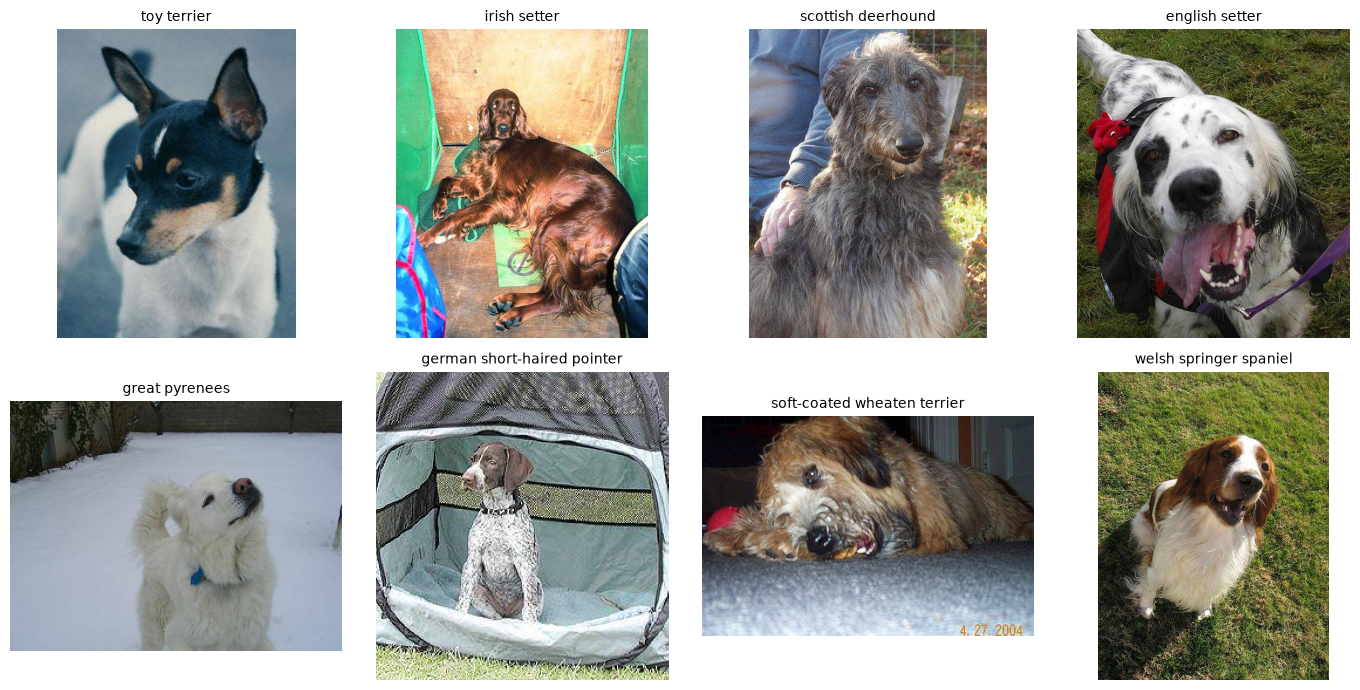

In [3]:
examples = labels.sample(n=min(8, len(labels)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis, row in zip(axes.flat, examples.itertuples(index=False)):
    with Image.open(DATA_DIR / "train" / f"{row.id}.jpg") as image:
        axis.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    axis.set_title(row.breed.replace("_", " "), fontsize=10)
    axis.axis("off")
for axis in axes.flat[len(examples):]:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 3. Séparer entraînement et validation

On réserve 20 % des images étiquetées avec une séparation **stratifiée** :
chaque race figure dans les deux groupes. `test/` n'a pas d'étiquettes et ne sert
donc pas à calculer une précision. La graine fixe rend cette séparation reproductible.

In [4]:
train_indices, val_indices = train_test_split(
    np.arange(len(labels)),
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=y,
)
assert not set(train_indices) & set(val_indices)
assert len(np.unique(y[train_indices])) == len(np.unique(y[val_indices])) == n_classes
print(f"Apprentissage : {len(train_indices):,} | validation : {len(val_indices):,}")

Apprentissage : 8,177 | validation : 2,045


## 4. Extraire les caractéristiques visuelles

EfficientNet reste figé en mode évaluation ; aucune étiquette de validation ou de test
n'intervient dans cette étape. Chaque image devient un vecteur de 1 280 valeurs.
Le redimensionnement et la normalisation sont ceux des poids préentraînés.

Le cache vérifie les identifiants et leur ordre, les versions des bibliothèques,
le prétraitement, ainsi que la taille et la date de modification de chaque image.
Mettre `FORCE_RECOMPUTE_FEATURES = True` pour forcer un nouveau calcul.

In [5]:
WEIGHTS = EfficientNet_B0_Weights.IMAGENET1K_V1
preprocess = WEIGHTS.transforms()
backbone = efficientnet_b0(weights=WEIGHTS)
feature_dim = backbone.classifier[1].in_features
backbone.classifier = nn.Identity()
backbone.requires_grad_(False)
backbone = backbone.to(DEVICE).eval()
if DEVICE.type == "cpu":
    backbone = backbone.to(memory_format=torch.channels_last)
print(f"Extracteur prêt : EfficientNet B0 | {feature_dim} caractéristiques par image")


class DogImages(Dataset):
    def __init__(self, image_ids, directory, transform):
        self.image_ids = list(image_ids)
        self.directory = Path(directory)
        self.transform = transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        path = self.directory / f"{self.image_ids[index]}.jpg"
        try:
            with Image.open(path) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                return self.transform(image)
        except (OSError, ValueError) as error:
            raise RuntimeError(f"Impossible de lire l'image {path}") from error


def feature_fingerprint(image_ids, directory):
    digest = hashlib.sha256()
    description = {
        "weights": WEIGHTS.name,
        "preprocess": repr(preprocess),
        "orientation": "ImageOps.exif_transpose",
        "torchvision": torchvision.__version__,
        "torch": torch.__version__,
        "directory": str(Path(directory).resolve()),
    }
    digest.update(json.dumps(description, sort_keys=True).encode())
    for image_id in image_ids:
        stat = (Path(directory) / f"{image_id}.jpg").stat()
        digest.update(f"{image_id}:{stat.st_size}:{stat.st_mtime_ns}\n".encode())
    return digest.hexdigest()


def extract_features(image_ids, directory, cache_name):
    image_ids = list(image_ids)
    cache_path = CACHE_DIR / f"{cache_name}.npz"
    fingerprint = feature_fingerprint(image_ids, directory)
    if cache_path.exists() and not FORCE_RECOMPUTE_FEATURES:
        with np.load(cache_path, allow_pickle=False) as cached:
            if (
                cached["fingerprint"].item() == fingerprint
                and np.array_equal(cached["ids"], np.asarray(image_ids))
                and cached["features"].shape == (len(image_ids), feature_dim)
                and np.isfinite(cached["features"]).all()
            ):
                print(f"Cache réutilisé : {cache_path.name}")
                return cached["features"].copy()

    dataset = DogImages(image_ids, directory, preprocess)
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
    )
    features = np.empty((len(dataset), feature_dim), dtype=np.float32)
    offset = 0
    start = time.perf_counter()
    backbone.eval()
    with torch.inference_mode():
        for images in tqdm(loader, desc=cache_name, mininterval=5):
            images = images.to(DEVICE, non_blocking=DEVICE.type == "cuda")
            if DEVICE.type == "cpu":
                images = images.contiguous(memory_format=torch.channels_last)
            batch = backbone(images).cpu().numpy()
            features[offset:offset + len(batch)] = batch
            offset += len(batch)
    if offset != len(dataset) or not np.isfinite(features).all():
        raise RuntimeError("Caractéristiques manquantes ou non finies.")
    temporary = cache_path.with_suffix(".tmp.npz")
    np.savez(temporary, features=features, ids=np.asarray(image_ids), fingerprint=fingerprint)
    temporary.replace(cache_path)
    print(f"{cache_name} : {features.shape} | {(time.perf_counter() - start) / 60:.1f} min")
    return features


X = extract_features(train_ids, DATA_DIR / "train", "train_efficientnet_b0")

Extracteur prêt : EfficientNet B0 | 1280 caractéristiques par image


train_efficientnet_b0: 100%|██████████| 320/320 [10:04<00:00,  1.89s/it]


train_efficientnet_b0 : (10222, 1280) | 10.1 min


## 5. Entraîner le classifieur et mesurer ses performances

La standardisation est apprise **uniquement sur l'entraînement**.
On compare deux forces de régularisation et conserve celle qui minimise la
**log loss**, qui tient compte de la qualité des probabilités.
L'accuracy top 1 mesure la proportion de races correctement prédites ;
le top 5 vérifie si la bonne race est parmi les cinq premières propositions.

Ce score est une validation interne utilisée pour choisir le paramètre `C` ;
il ne représente pas une évaluation indépendante sur `test/`.

In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X[train_indices])
X_val = scaler.transform(X[val_indices])
y_train, y_val = y[train_indices], y[val_indices]
results = []
best_log_loss = float("inf")

with threadpool_limits(limits=CPU_THREADS):
    for c_value in C_VALUES:
        candidate = LogisticRegression(C=c_value, max_iter=MAX_ITER, tol=1e-3, solver="lbfgs")
        started = time.perf_counter()
        candidate.fit(X_train, y_train)
        assert np.array_equal(candidate.classes_, np.arange(n_classes))
        probabilities = candidate.predict_proba(X_val)
        score = log_loss(y_val, probabilities, labels=np.arange(n_classes))
        result = {
            "C": c_value,
            "log_loss": score,
            "accuracy_top1": accuracy_score(y_val, probabilities.argmax(axis=1)),
            "accuracy_top5": top_k_accuracy_score(y_val, probabilities, k=5, labels=np.arange(n_classes)),
            "iterations": int(candidate.n_iter_.max()),
        }
        results.append(result)
        print(f"C={c_value:g} | log loss={score:.4f} | accuracy={result['accuracy_top1']:.2%} | {time.perf_counter() - started:.1f} s")
        if result["iterations"] >= MAX_ITER:
            print("Limite d'itérations atteinte : augmenter MAX_ITER si nécessaire.")
        if score < best_log_loss:
            best_log_loss = score
            validation_classifier = candidate
            val_probabilities = probabilities
            best_c = c_value

validation_results = pd.DataFrame(results).sort_values("log_loss").reset_index(drop=True)
display(validation_results)
best_result = next(result for result in results if result["C"] == best_c)
metrics = {
    "seed": SEED,
    "validation_fraction": VALIDATION_SIZE,
    "training_images": len(train_indices),
    "validation_images": len(val_indices),
    "num_classes": n_classes,
    "selected_C": best_c,
    "validation": best_result,
    "candidates": results,
    "evaluation": "internal_stratified_holdout_used_for_C_selection",
}
(ARTIFACT_DIR / "validation_metrics.json").write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8"
)

val_predictions = labels.iloc[val_indices].copy()
val_predictions["predicted_breed"] = np.asarray(class_names)[val_probabilities.argmax(axis=1)]
val_predictions["confidence"] = val_probabilities.max(axis=1)
val_predictions["correct"] = val_predictions["breed"] == val_predictions["predicted_breed"]
val_predictions.to_csv(ARTIFACT_DIR / "validation_predictions.csv", index=False)
print(f"Paramètre retenu : C={best_c:g}")

C=0.01 | log loss=0.4038 | accuracy=88.61% | 3.0 s
C=0.1 | log loss=0.3893 | accuracy=88.41% | 1.8 s


,C,log_loss,accuracy_top1,accuracy_top5,iterations
0,0.10,0.389335,0.884108,0.991687,16
1,0.01,0.403769,0.886064,0.992176,18


Paramètre retenu : C=0.1


In [7]:
per_breed = val_predictions.groupby("breed")["correct"].agg(["count", "mean"])
per_breed.columns = ["images_validation", "accuracy"]
print("Races les plus difficiles sur cette séparation (peu d'images par race) :")
display(per_breed.sort_values("accuracy").head(10))
print("Exemples d'erreurs :")
display(val_predictions.loc[~val_predictions["correct"]].sort_values("confidence", ascending=False).head(10))

Races les plus difficiles sur cette séparation (peu d'images par race) :


,images_validation,accuracy
breed,,
eskimo_dog,13,0.230769
walker_hound,14,0.428571
miniature_poodle,16,0.437500
collie,17,0.529412
appenzeller,16,0.562500
siberian_husky,19,0.631579
lhasa,18,0.666667
staffordshire_bullterrier,16,0.687500
wire-haired_fox_terrier,16,0.687500


Exemples d'erreurs :


,id,breed,predicted_breed,confidence,correct
3302,5201cf397c9fb94bede2b6305bda9fff,standard_schnauzer,miniature_schnauzer,0.998674,False
4871,7a23cdc4394b4161738def43eab00254,staffordshire_bullterrier,american_staffordshire_terrier,0.998165,False
10022,fb6bca9a75ead518333fd3c98aa4dc40,kuvasz,great_pyrenees,0.995540,False
1981,30e13c562674d156443f1466a7a219b5,lhasa,tibetan_terrier,0.994151,False
1448,2428c868173d32dcbbd766fe44c141e4,walker_hound,basset,0.993610,False
9029,e2d770fe32772edb9dba937c009f3e4d,miniature_poodle,toy_poodle,0.991490,False
2074,33d3d86055b02fe7f097e3654fd42d3a,lhasa,toy_poodle,0.991375,False
9925,f97b9b8848683ab240cffeda2c855502,entlebucher,greater_swiss_mountain_dog,0.991098,False
8588,d7750c85b3e5d0b3cb7adaffa5474a11,wire-haired_fox_terrier,lakeland_terrier,0.990752,False
6814,ab1b5ed3e3894eb6caa70609add09443,ibizan_hound,whippet,0.989840,False


## 6. Réentraîner sur toutes les images étiquetées et sauvegarder

Une fois le paramètre choisi, on réapprend la standardisation et le classifieur
sur la totalité de `train/`. La précision annoncée ci-dessus reste celle du modèle
de validation, avant ce réentraînement final.

On fusionne la standardisation et la régression logistique dans une couche linéaire
PyTorch, puis on sauvegarde les poids complets du réseau et l'ordre des races.
Le modèle exporté pourra être rechargé sans télécharger de nouveaux poids.

In [8]:
final_scaler = StandardScaler()
X_all = final_scaler.fit_transform(X)
final_classifier = LogisticRegression(C=best_c, max_iter=MAX_ITER, tol=1e-3, solver="lbfgs")
with threadpool_limits(limits=CPU_THREADS):
    final_classifier.fit(X_all, y)
assert np.array_equal(final_classifier.classes_, np.arange(n_classes))
if final_classifier.n_iter_.max() >= MAX_ITER:
    print("Le modèle final a atteint MAX_ITER ; augmenter cette valeur si besoin.")

# Fusion exacte : W * ((x - mean) / scale) + b = W_raw * x + b_raw.
raw_weight = final_classifier.coef_ / final_scaler.scale_[None, :]
raw_bias = final_classifier.intercept_ - raw_weight @ final_scaler.mean_
linear_head = nn.Linear(feature_dim, n_classes)
with torch.no_grad():
    linear_head.weight.copy_(torch.as_tensor(raw_weight, dtype=torch.float32))
    linear_head.bias.copy_(torch.as_tensor(raw_bias, dtype=torch.float32))

def head_probabilities(features):
    with torch.inference_mode():
        return linear_head(torch.as_tensor(features, dtype=torch.float32)).softmax(dim=1).numpy()

reference = final_classifier.predict_proba(final_scaler.transform(X[:32]))
np.testing.assert_allclose(head_probabilities(X[:32]), reference, rtol=1e-4, atol=2e-5)

model = nn.Sequential(backbone.cpu(), linear_head.cpu()).eval()
model_path = ARTIFACT_DIR / "dog_breed_model.pth"
checkpoint = {
    "format_version": 1,
    "architecture": "efficientnet_b0_linear",
    "pretrained_weights": WEIGHTS.name,
    "class_names": class_names,
    "feature_dim": feature_dim,
    "num_training_images": len(labels),
    "selected_C": best_c,
    "validation_metrics": metrics,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "state_dict": model.state_dict(),
}
temporary_model_path = model_path.with_suffix(".tmp.pth")
torch.save(checkpoint, temporary_model_path)
temporary_model_path.replace(model_path)
backbone.to(DEVICE).eval()
print(f"Modèle entraîné sur {len(labels):,} images et sauvegardé : {model_path}")

Modèle entraîné sur 10,222 images et sauvegardé : C:\Users\Ahmed\Documents\GitHub\dog_breed_classification\artifacts\dog_breed_model.pth


## 7. Prédire les images de test et créer `submission.csv`

Les lignes et colonnes sont reprises exactement dans l'ordre de
`sample_submission.csv`. Les contrôles vérifient les dimensions, les identifiants,
les probabilités et leur somme avant d'écrire le CSV.

In [9]:
X_test = extract_features(test_ids, DATA_DIR / "test", "test_efficientnet_b0")
test_probabilities = np.vstack([
    head_probabilities(X_test[start:start + 1024])
    for start in range(0, len(X_test), 1024)
])
assert test_probabilities.shape == (len(sample), n_classes)
assert np.isfinite(test_probabilities).all()
assert (test_probabilities >= 0).all() and (test_probabilities <= 1).all()
np.testing.assert_allclose(test_probabilities.sum(axis=1), 1.0, atol=1e-5)

submission = pd.DataFrame(test_probabilities, columns=class_names)
submission.insert(0, "id", sample["id"].to_numpy())
assert submission.columns.tolist() == sample.columns.tolist()
assert submission["id"].equals(sample["id"])
assert submission.shape == sample.shape
submission_path = DATA_DIR / "submission.csv"
temporary_submission = submission_path.with_suffix(".tmp.csv")
submission.to_csv(temporary_submission, index=False, float_format="%.9g")
temporary_submission.replace(submission_path)

# Vérifier aussi le contenu réellement écrit sur disque.
saved_submission = pd.read_csv(submission_path, dtype={"id": str})
assert saved_submission.columns.tolist() == sample.columns.tolist()
assert saved_submission["id"].equals(sample["id"])
saved_probabilities = saved_submission[class_names].to_numpy()
assert np.isfinite(saved_probabilities).all()
assert (saved_probabilities >= 0).all() and (saved_probabilities <= 1).all()
np.testing.assert_allclose(saved_probabilities.sum(axis=1), 1.0, atol=1e-5)
print(f"Soumission prête : {submission_path} | {submission.shape[0]:,} lignes, {submission.shape[1]} colonnes")
display(submission.iloc[:5, :7])

test_efficientnet_b0: 100%|██████████| 324/324 [08:04<00:00,  1.50s/it]


test_efficientnet_b0 : (10357, 1280) | 8.1 min
Soumission prête : C:\Users\Ahmed\Documents\GitHub\dog_breed_classification\submission.csv | 10,357 lignes, 121 colonnes


,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller
0,000621fb3cbb32d8935728e48679680e,1.415686e-07,1.068760e-08,4.855336e-10,9.141967e-10,9.448238e-11,3.506913e-10
1,00102ee9d8eb90812350685311fe5890,4.798795e-09,3.911174e-09,1.645147e-08,3.522967e-09,7.004480e-09,3.583541e-09
2,0012a730dfa437f5f3613fb75efcd4ce,2.262517e-07,2.534299e-04,1.466578e-07,4.453231e-08,3.515936e-08,7.499624e-08
3,001510bc8570bbeee98c8d80c8a95ec1,1.979190e-04,4.918840e-09,3.655958e-09,1.320378e-09,1.612321e-05,1.620512e-09
4,001a5f3114548acdefa3d4da05474c2e,3.110177e-04,1.138003e-07,9.328518e-08,6.970867e-09,4.738456e-07,8.079486e-09


## 8. Recharger le modèle et prédire une nouvelle photo

Après un redémarrage du noyau, il suffit d'exécuter la cellule des imports puis
les cellules de cette section : aucun réentraînement n'est nécessaire.
`predict_breed("chemin/vers/mon_chien.jpg")` retourne les cinq races les plus probables.
Ce modèle choisit parmi les races apprises ; il ne vérifie pas qu'une photo contient un chien.

In [10]:
def load_dog_model(path=ARTIFACT_DIR / "dog_breed_model.pth", device=DEVICE):
    saved = torch.load(path, map_location="cpu", weights_only=True)
    if saved["architecture"] != "efficientnet_b0_linear":
        raise ValueError("Architecture de modèle non prise en charge.")
    extractor = efficientnet_b0(weights=None)
    extractor.classifier = nn.Identity()
    restored = nn.Sequential(extractor, nn.Linear(saved["feature_dim"], len(saved["class_names"])))
    restored.load_state_dict(saved["state_dict"])
    restored = restored.to(device).eval()
    transform = EfficientNet_B0_Weights[saved["pretrained_weights"]].transforms()
    return restored, saved["class_names"], transform


prediction_model, prediction_classes, prediction_transform = load_dog_model()


def predict_breed(image_path, top_k=5):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(image_path)
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        tensor = prediction_transform(image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        probabilities = prediction_model(tensor).softmax(dim=1).cpu().numpy()[0]
    top_indices = np.argsort(probabilities)[::-1][:max(1, min(int(top_k), len(prediction_classes)))]
    return pd.DataFrame({
        "race": [prediction_classes[index] for index in top_indices],
        "probabilite": probabilities[top_indices],
    })


example_id = pd.read_csv(
    DATA_DIR / "sample_submission.csv", usecols=["id"], dtype={"id": str}, nrows=1
).iloc[0]["id"]
example_path = DATA_DIR / "test" / f"{example_id}.jpg"
example_predictions = predict_breed(example_path, top_k=5)
display(example_predictions)

# En exécution complète, comparer aussi au résultat obtenu avant rechargement.
if "test_probabilities" in globals():
    with Image.open(example_path) as image:
        image_tensor = prediction_transform(ImageOps.exif_transpose(image).convert("RGB")).unsqueeze(0)
    with torch.inference_mode():
        restored_probabilities = prediction_model(image_tensor.to(DEVICE)).softmax(dim=1).cpu().numpy()[0]
    np.testing.assert_allclose(restored_probabilities, test_probabilities[0], rtol=1e-3, atol=3e-5)
    print("Vérification du modèle rechargé : OK")

,race,probabilite
0,japanese_spaniel,0.990045
1,pekinese,0.009818
2,shih-tzu,0.000086
3,blenheim_spaniel,0.000034
4,papillon,0.000011


Vérification du modèle rechargé : OK


## Utilisation et limites

- `submission.csv` contient les probabilités pour toutes les images de `test/`.
- `artifacts/dog_breed_model.pth` contient le modèle complet et la liste des races.
- `artifacts/validation_metrics.json` conserve les scores mesurés sur le groupe de validation.
- Les caches dans `artifacts/features/` accélèrent les exécutions suivantes.
- Le modèle utilise les 120 races présentes dans les données ; les races proches et les chiens croisés
  peuvent être difficiles à distinguer. La probabilité maximale n'est pas une garantie de justesse.
- Pour améliorer ensuite le score, on peut tester un réseau plus grand ou ajuster ses dernières
  couches avec augmentation des images, de préférence sur GPU, puis comparer avec la même séparation.

Références : [EfficientNet B0 et son prétraitement](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html),
[apprentissage par transfert avec PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).